# Does the steerability screen predict distillation transfer across receivers and teachers?

**Question.** The steerability screen injects a teacher-derived steering vector into a *base*
receiver model and measures how much animal preference it can induce. If that screen is a
usable cheap proxy, then (a) receivers that steer better should distil better, and (b) within a
receiver — and across a wide teacher population — teachers whose vectors steer better should
distil better. This notebook tests both.

**Headline steerability metric.** `peaks.gated_off.delta_val_p_mean`: the peak over the
(layer x alpha) grid *restricted to grid points that pass the off-topic leakage gate*,
selected on the `favorite` prompt set and reported on the held-out `validation` set, minus the
base's unsteered validation p(dog). The ungated peak is kept as a secondary column.
The screen's `teacher_val_p_mean` column is **not** used as a predictor anywhere: it is
saturated at ~1.0 for every teacher in every population here, so it carries no ranking
information (stated once here, quantified in the caveat cell).

**Section 1 — receivers.**
- **Teachers:** the 10 `param_tags` of `run_logs/dog_top10_kband_configs.json` — dog, finetuned
  on the *original* pythia-160m, teacher ftseed 1.
- **Receivers (8):** `orig`, `ds1`/`ds2`/`ds3` (data-seed re-runs), `fs1`/`fs2`/`fs3` (full
  re-seeded inits), and `wc1` (weightc-seed1), which has a screen but **no transfer side** —
  its endpoint student tree contains none of the shared cells.
- **Screen:** `teachers/dog/pythia-160m/{tag}/steerability/{subdir}/aggregate.json`, seed 1.
- **Transfer:** student cells at
  `students/dog/{receiver}/teacher-pythia-160m/{tag}_tseed1/ex10-20_prefix_n100k/{cell}/ftseed*/`,
  score = `sets.test.p_target`. Restricted to the **56 student cells present for all 10 teachers
  x orig/ds1/fs1** (the original intersection; asserted also present for ds2/ds3/fs2/fs3).
  Aggregation is **per cell first** (mean over ftseeds inside a cell), then mean/median over
  the 56 cells.
- **Prior reference:** `transfer_factors.load_priors` `test_prior` per receiver base. There is
  no `weightc-seed1` prior entry, so wc1's x-prior column is NaN.

**Section 2 — teachers.** All dog orig teachers with a student tree (102 today), self-screen
vs transfer measured on the student cells **shared by every teacher in the section**
(`SHARED2`); cells that only some teachers have are ignored.

Date: 2026-09-12.

In [1]:
import json
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr

from subliminal_learning.config import load_paths_local

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

OUT = Path(load_paths_local()["output_root"])
TAGS = json.loads(Path("../run_logs/dog_top10_kband_configs.json").read_text())["param_tags"]

# receiver label -> (students base dir or None, steerability subdir, base_label for load_priors)
RECV = {
    "orig": ("pythia-160m", "self", "original"),
    "ds1": ("pythia-160m-data-seed1", "steer_data-seed1", "data-seed1"),
    "ds2": ("pythia-160m-data-seed2", "steer_data-seed2", "data-seed2"),
    "ds3": ("pythia-160m-data-seed3", "steer_data-seed3", "data-seed3"),
    "fs1": ("pythia-160m-seed1", "steer_full-seed1", "full-seed1"),
    "fs2": ("pythia-160m-seed2", "steer_full-seed2", "full-seed2"),
    "fs3": ("pythia-160m-seed3", "steer_full-seed3", "full-seed3"),
    "wc1": (None, "steer_weightc-seed1", "weightc-seed1"),  # screen only, no transfer side
}
XFER = [r for r, (b, _s, _p) in RECV.items() if b is not None]  # 7 receivers with transfer
CORE = ["orig", "ds1", "fs1"]  # receivers that DEFINE the shared-cell intersection
POOL = "ex10-20_prefix_n100k"
print(OUT, len(TAGS), "teachers,", len(RECV), "receivers (", len(XFER), "with transfer )")

/mnt/cold-1/soar-subliminal/angela/outputs 10 teachers, 8 receivers ( 7 with transfer )


In [2]:
def screen_row(tag: str, subdir: str) -> dict | None:
    """One steerability-screen aggregate: peak-over-grid, selected on favorite, reported on validation."""
    f = OUT / "teachers/dog/pythia-160m" / tag / "steerability" / subdir / "aggregate.json"
    if not f.exists():
        return None
    d = json.loads(f.read_text())
    pk = d["peaks"]
    return {
        "gated_off_delta": pk["gated_off"]["delta_val_p_mean"],
        "gated_off_n": pk["gated_off"]["gated_n"],
        "ungated_delta": pk["ungated"]["delta_val_p_mean"],
        "gated_neg_off_delta": pk["gated_neg_off"]["delta_val_p_mean"],
        "gated_neg_off_n": pk["gated_neg_off"]["gated_n"],
        "teacher_val_p": d["teacher_val_p_mean"],
        "base_val_p": d["base_val_p"],
        "selection_set": d["selection_set"],
    }


def cell_scores(tag: str, base_dir: str, teacher_dir: str = "teacher-pythia-160m") -> dict[str, float]:
    """cell -> mean test p_target over that cell's ftseeds (per-cell-first aggregation)."""
    root = OUT / "students/dog" / base_dir / teacher_dir / f"{tag}_tseed1" / POOL
    out = {}
    if not root.exists():
        return out
    for cell in sorted(root.iterdir()):
        if not cell.is_dir() or cell.name == "eas":
            continue
        vals = []
        for seed in sorted(cell.glob("ftseed*")):
            f = seed / "eval" / "preference_eval.json"
            if not f.exists():
                f = seed / "preference_eval.json"
            if f.exists():
                vals.append(float(json.loads(f.read_text())["sets"]["test"]["p_target"]))
        if vals:
            out[cell.name] = float(np.mean(vals))
    return out


CELLS = {(r, t): cell_scores(t, RECV[r][0]) for r in XFER for t in TAGS}
SHARED = sorted(set.intersection(*(set(CELLS[(r, t)]) for r in CORE for t in TAGS)))
assert len(SHARED) == 56, len(SHARED)
for r in XFER:
    for t in TAGS:
        missing = [c for c in SHARED if c not in CELLS[(r, t)]]
        assert not missing, (r, t, missing[:3])
print(f"{len(SHARED)} shared cells (intersection over orig/ds1/fs1 x 10 teachers);")
print(f"all {len(SHARED)} also present for every one of the {len(XFER)} transfer receivers.")

56 shared cells (intersection over orig/ds1/fs1 x 10 teachers);
all 56 also present for every one of the 7 transfer receivers.


In [3]:
from subliminal_learning.analysis.transfer_factors import load_priors

_pri = load_priors(OUT)
_pri = _pri[_pri["animal"] == "dog"].set_index("base_label")["test_prior"]
PRIOR = {r: (float(_pri[p]) if p in _pri.index and np.isfinite(_pri[p]) else np.nan)
         for r, (_b, _s, p) in RECV.items()}
print("dog test_prior per receiver base (load_priors `test_prior`; NaN = no prior entry):")
print(pd.Series(PRIOR).round(5).to_string())

dog test_prior per receiver base (load_priors `test_prior`; NaN = no prior entry):
orig    0.00963
ds1     0.01332
ds2     0.01095
ds3     0.00899
fs1     0.00817
fs2     0.00843
fs3     0.01061
wc1         NaN


In [4]:
rows = []
for r, (b, sub, _p) in RECV.items():
    for t in TAGS:
        sc = screen_row(t, sub)
        assert sc is not None, (t, sub)
        if b is None:
            xf = {"transfer_mean": np.nan, "transfer_median": np.nan,
                  "transfer_mean_x_prior": np.nan, "n_cells": 0}
        else:
            v = np.array([CELLS[(r, t)][c] for c in SHARED])
            xf = {"transfer_mean": v.mean(), "transfer_median": float(np.median(v)),
                  "transfer_mean_x_prior": v.mean() / PRIOR[r], "n_cells": len(v)}
        rows.append({"receiver": r, "teacher": t, **xf, **sc})
df = pd.DataFrame(rows)

print("Row unit: one (receiver, teacher) pair. 8 receivers x 10 teachers = 80 rows;")
print("  wc1's 10 rows have NaN transfer (screen only -- no student tree with the shared cells).")
print("transfer_mean/median: mean/median over the 56 SHARED student cells of the per-cell mean")
print("  test p(dog) (mean over that cell's ftseeds first). transfer_mean_x_prior divides by that")
print("  receiver base's own dog test prior; NaN for wc1 (no prior entry).")
print("Screen columns: peak over the (layer x alpha) grid selected on `favorite`, reported on")
print("  `validation`, minus base_val_p. HEADLINE = gated_off_delta (off-topic-gated); gated_*_n")
print("  = how many grid points passed the gate. Selection: the 10 top-10 kband dog teachers.")
df.round(4)

Row unit: one (receiver, teacher) pair. 8 receivers x 10 teachers = 80 rows;
  wc1's 10 rows have NaN transfer (screen only -- no student tree with the shared cells).
transfer_mean/median: mean/median over the 56 SHARED student cells of the per-cell mean
  test p(dog) (mean over that cell's ftseeds first). transfer_mean_x_prior divides by that
  receiver base's own dog test prior; NaN for wc1 (no prior entry).
Screen columns: peak over the (layer x alpha) grid selected on `favorite`, reported on
  `validation`, minus base_val_p. HEADLINE = gated_off_delta (off-topic-gated); gated_*_n
  = how many grid points passed the gate. Selection: the 10 top-10 kband dog teachers.


,receiver,teacher,transfer_mean,transfer_median,transfer_mean_x_prior,n_cells,gated_off_delta,gated_off_n,ungated_delta,gated_neg_off_delta,gated_neg_off_n,teacher_val_p,base_val_p,selection_set
0,orig,ep20_lr1e-4_r16a32,0.7078,0.7537,73.5249,56,0.8894,1,0.9903,0.0888,1,1.0000,0.0097,favorite
1,orig,ep2_lr5e-4_r32a64,0.6080,0.5912,63.1606,56,0.9008,1,0.9862,0.1026,1,0.9998,0.0097,favorite
2,orig,ep7_lr5e-4_r8a8,0.7003,0.7315,72.7483,56,0.9811,1,0.9888,0.0888,1,0.9999,0.0097,favorite
3,orig,ep10_lr1e-4_r64a64,0.6373,0.6536,66.1952,56,0.8839,1,0.9903,0.0958,1,1.0000,0.0097,favorite
4,orig,ep20_lr1e-4_r8a16,0.5397,0.5492,56.0614,56,0.9198,1,0.9881,0.0778,1,0.9999,0.0097,favorite
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,wc1,ep5_lr5e-4_r8a16,NaN,NaN,NaN,0,0.0022,1,0.0022,0.0022,1,0.9996,0.0094,favorite
76,wc1,ep5_lr2e-4_r64a64,NaN,NaN,NaN,0,0.0021,1,0.0021,0.0021,1,0.9999,0.0094,favorite
77,wc1,ep7_lr2e-4_r32a32,NaN,NaN,NaN,0,0.0037,1,0.0037,0.0037,1,1.0000,0.0094,favorite
78,wc1,ep10_lr1e-4_r32a64,NaN,NaN,NaN,0,0.0048,1,0.0048,0.0048,1,1.0000,0.0094,favorite


In [5]:
SCREEN = ["gated_off_delta", "ungated_delta", "gated_neg_off_delta"]
out = []
for r in list(RECV) + ["POOLED"]:
    d = df[df["receiver"].isin(XFER)] if r == "POOLED" else df[df["receiver"] == r]
    d = d.dropna(subset=["transfer_mean"])
    row = {"group": r, "n": len(d)}
    for m in SCREEN:
        if len(d) < 3 or d[m].nunique() < 2:
            row[f"{m}|spearman"] = np.nan
            row[f"{m}|pearson"] = np.nan
        else:
            row[f"{m}|spearman"] = spearmanr(d["transfer_mean"], d[m]).statistic
            row[f"{m}|pearson"] = pearsonr(d["transfer_mean"], d[m]).statistic
    out.append(row)
corr = pd.DataFrame(out).set_index("group")

print("Row unit: one receiver (n=10 teachers each), plus POOLED = the 7 transfer receivers x 10")
print("  teachers = 70 rows. wc1 has no transfer, so its row is n=0 / NaN by construction.")
print("Columns: Spearman / Pearson of transfer_mean (mean test p(dog) over the 56 shared cells,")
print("  per-cell-first) against each screen metric. HEADLINE metric = gated_off_delta.")
print("IMPORTANT: the POOLED row is dominated by the RECEIVER level, not by teacher ranking --")
print("  it mostly re-expresses the between-receiver ordering. The per-receiver rows are the")
print("  informative test of whether the screen RANKS TEACHERS.")
corr.round(3)

Row unit: one receiver (n=10 teachers each), plus POOLED = the 7 transfer receivers x 10
  teachers = 70 rows. wc1 has no transfer, so its row is n=0 / NaN by construction.
Columns: Spearman / Pearson of transfer_mean (mean test p(dog) over the 56 shared cells,
  per-cell-first) against each screen metric. HEADLINE metric = gated_off_delta.
IMPORTANT: the POOLED row is dominated by the RECEIVER level, not by teacher ranking --
  it mostly re-expresses the between-receiver ordering. The per-receiver rows are the
  informative test of whether the screen RANKS TEACHERS.


,n,gated_off_delta|spearman,gated_off_delta|pearson,ungated_delta|spearman,ungated_delta|pearson,gated_neg_off_delta|spearman,gated_neg_off_delta|pearson
group,,,,,,,
orig,10,-0.297,-0.164,0.406,0.223,0.261,0.285
ds1,10,0.442,0.598,0.442,0.598,0.079,-0.444
ds2,10,0.115,0.124,-0.103,0.027,-0.321,-0.121
ds3,10,-0.539,-0.411,-0.382,-0.177,-0.164,0.081
fs1,10,-0.079,-0.243,-0.079,-0.243,-0.079,-0.243
fs2,10,-0.212,-0.010,-0.212,-0.010,-0.212,-0.010
fs3,10,-0.285,-0.291,-0.285,-0.291,-0.285,-0.291
wc1,0,NaN,NaN,NaN,NaN,NaN,NaN
POOLED,70,0.874,0.603,0.875,0.606,0.753,0.423


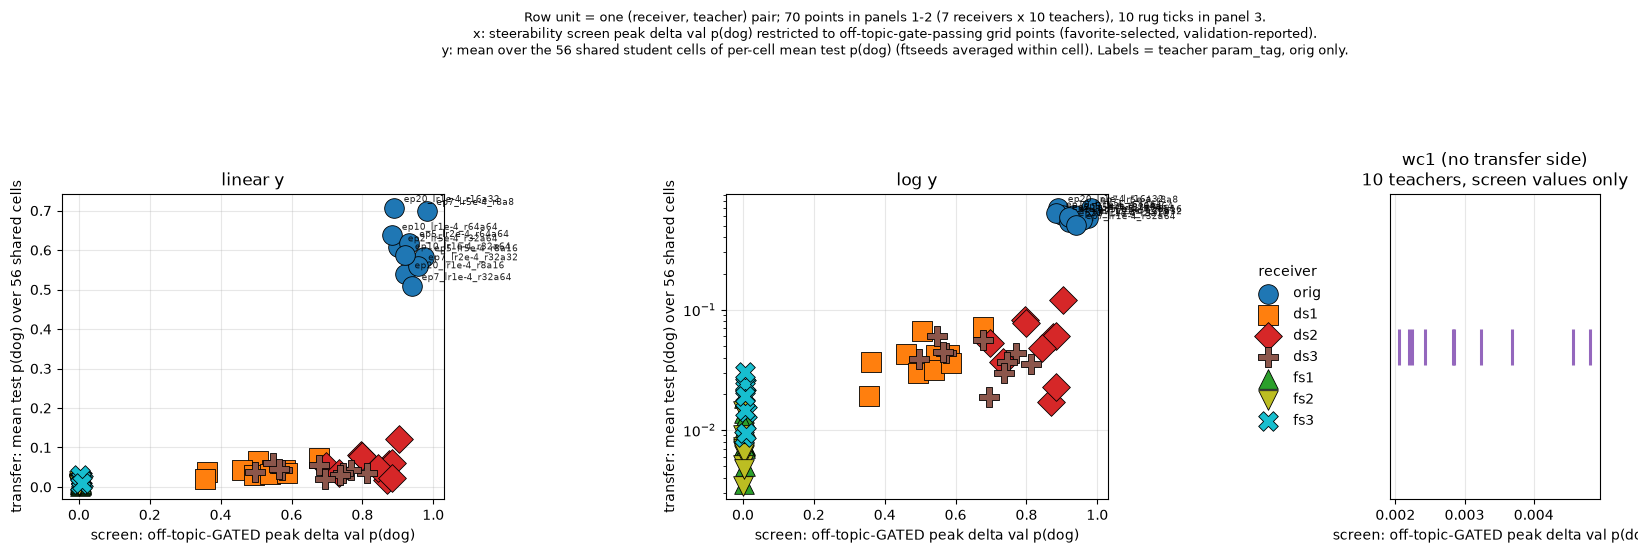

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), gridspec_kw={"width_ratios": [1, 1, 0.55]})
MARKS = {"orig": "o", "ds1": "s", "ds2": "D", "ds3": "P", "fs1": "^", "fs2": "v", "fs3": "X"}
COLS = {"orig": "tab:blue", "ds1": "tab:orange", "ds2": "tab:red", "ds3": "tab:brown",
        "fs1": "tab:green", "fs2": "tab:olive", "fs3": "tab:cyan"}
for ax, logy in zip(axes[:2], [False, True]):
    for r in XFER:
        d = df[df["receiver"] == r]
        ax.scatter(d["gated_off_delta"], d["transfer_mean"], s=200, marker=MARKS[r],
                   color=COLS[r], edgecolor="black", linewidth=0.6, label=r, zorder=3)
    for _, row in df[df["receiver"] == "orig"].iterrows():  # annotate orig only (else unreadable)
        ax.annotate(row["teacher"], (row["gated_off_delta"], row["transfer_mean"]),
                    textcoords="offset points", xytext=(7, 4), fontsize=6.5, alpha=0.85)
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("screen: off-topic-GATED peak delta val p(dog)")
    ax.set_ylabel("transfer: mean test p(dog) over 56 shared cells")
    ax.set_title("log y" if logy else "linear y")
    ax.grid(alpha=0.3)
axes[1].legend(title="receiver", loc="center left", bbox_to_anchor=(1.35, 0.5), frameon=False)

wc = df[df["receiver"] == "wc1"]["gated_off_delta"].to_numpy()
axes[2].plot(wc, np.zeros_like(wc), "|", markersize=26, markeredgewidth=2.2, color="tab:purple")
axes[2].set_yticks([])
axes[2].set_ylim(-1, 1)
axes[2].set_xlabel("screen: off-topic-GATED peak delta val p(dog)")
axes[2].set_title("wc1 (no transfer side)\n10 teachers, screen values only")
axes[2].grid(alpha=0.3, axis="x")

fig.suptitle("Row unit = one (receiver, teacher) pair; 70 points in panels 1-2 (7 receivers x 10 "
             "teachers), 10 rug ticks in panel 3.\nx: steerability screen peak delta val p(dog) "
             "restricted to off-topic-gate-passing grid points (favorite-selected, "
             "validation-reported).\ny: mean over the 56 shared student cells of per-cell mean "
             "test p(dog) (ftseeds averaged within cell). Labels = teacher param_tag, orig only.",
             fontsize=9)
fig.tight_layout(rect=(0, 0, 0.9, 0.87))
plt.show()

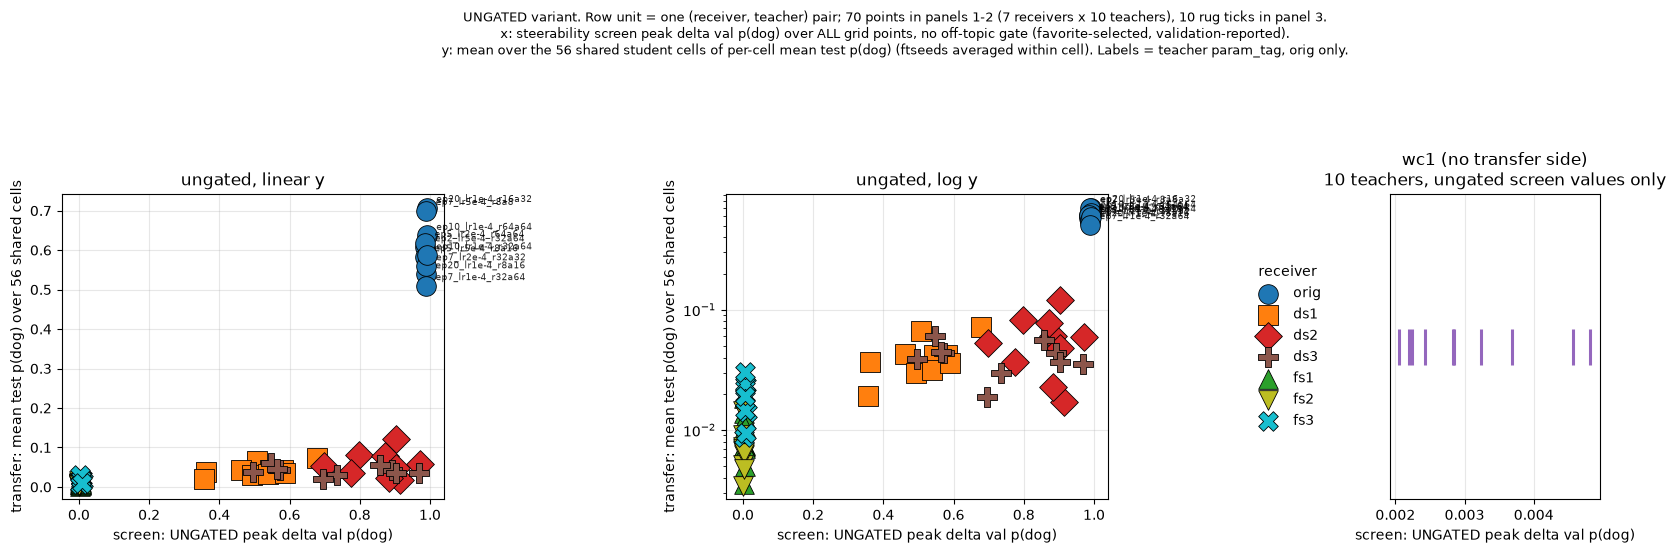

In [7]:
# UNGATED counterpart of the figure above (same panels/markers/legend), x = ungated_delta.
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), gridspec_kw={"width_ratios": [1, 1, 0.55]})
for ax, logy in zip(axes[:2], [False, True]):
    for r in XFER:
        d = df[df["receiver"] == r]
        ax.scatter(d["ungated_delta"], d["transfer_mean"], s=200, marker=MARKS[r],
                   color=COLS[r], edgecolor="black", linewidth=0.6, label=r, zorder=3)
    for _, row in df[df["receiver"] == "orig"].iterrows():  # annotate orig only (else unreadable)
        ax.annotate(row["teacher"], (row["ungated_delta"], row["transfer_mean"]),
                    textcoords="offset points", xytext=(7, 4), fontsize=6.5, alpha=0.85)
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("screen: UNGATED peak delta val p(dog)")
    ax.set_ylabel("transfer: mean test p(dog) over 56 shared cells")
    ax.set_title("ungated, log y" if logy else "ungated, linear y")
    ax.grid(alpha=0.3)
axes[1].legend(title="receiver", loc="center left", bbox_to_anchor=(1.35, 0.5), frameon=False)

wc = df[df["receiver"] == "wc1"]["ungated_delta"].to_numpy()
axes[2].plot(wc, np.zeros_like(wc), "|", markersize=26, markeredgewidth=2.2, color="tab:purple")
axes[2].set_yticks([])
axes[2].set_ylim(-1, 1)
axes[2].set_xlabel("screen: UNGATED peak delta val p(dog)")
axes[2].set_title("wc1 (no transfer side)\n10 teachers, ungated screen values only")
axes[2].grid(alpha=0.3, axis="x")

fig.suptitle("UNGATED variant. Row unit = one (receiver, teacher) pair; 70 points in panels 1-2 "
             "(7 receivers x 10 teachers), 10 rug ticks in panel 3.\nx: steerability screen peak "
             "delta val p(dog) over ALL grid points, no off-topic gate (favorite-selected, "
             "validation-reported).\ny: mean over the 56 shared student cells of per-cell mean "
             "test p(dog) (ftseeds averaged within cell). Labels = teacher param_tag, orig only.",
             fontsize=9)
fig.tight_layout(rect=(0, 0, 0.9, 0.87))
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)
fig.savefig(FIGDIR / "steerability_vs_transfer_ungated_receivers.png", dpi=150,
            bbox_inches="tight")
plt.show()


In [8]:
summ = (df.groupby("receiver")
          .agg(mean_transfer=("transfer_mean", "mean"),
               mean_transfer_x_prior=("transfer_mean_x_prior", "mean"),
               mean_gated_off_delta=("gated_off_delta", "mean"),
               mean_ungated_delta=("ungated_delta", "mean"),
               mean_base_val_p=("base_val_p", "mean"),
               mean_gated_off_n=("gated_off_n", "mean"),
               test_prior=("receiver", lambda s: PRIOR[s.iloc[0]]))
          .loc[list(RECV)])

print("Row unit: one receiver (aggregate over its 10 top-10 kband teachers). 8 rows.")
print("mean_transfer: mean over 10 teachers of the teacher's mean over the 56 shared cells")
print("  (per-cell-first). NaN for wc1 -- no transfer side.")
print("mean_transfer_x_prior: same, in multiples of that receiver base's dog test prior;")
print("  NaN for wc1 (no `weightc-seed1` prior entry in load_priors).")
print("mean_gated_off_delta (HEADLINE) / mean_ungated_delta: mean over teachers of the screen peak.")
print("mean_base_val_p: the receiver base's unsteered validation p(dog) (constant per receiver).")
print("mean_gated_off_n: mean number of grid points surviving the off-topic gate.")
summ.round(4)

Row unit: one receiver (aggregate over its 10 top-10 kband teachers). 8 rows.
mean_transfer: mean over 10 teachers of the teacher's mean over the 56 shared cells
  (per-cell-first). NaN for wc1 -- no transfer side.
mean_transfer_x_prior: same, in multiples of that receiver base's dog test prior;
  NaN for wc1 (no `weightc-seed1` prior entry in load_priors).
mean_gated_off_delta (HEADLINE) / mean_ungated_delta: mean over teachers of the screen peak.
mean_base_val_p: the receiver base's unsteered validation p(dog) (constant per receiver).
mean_gated_off_n: mean number of grid points surviving the off-topic gate.


,mean_transfer,mean_transfer_x_prior,mean_gated_off_delta,mean_ungated_delta,mean_base_val_p,mean_gated_off_n,test_prior
receiver,,,,,,,
orig,0.6053,62.8751,0.9302,0.9882,0.0097,1.0,0.0096
ds1,0.0419,3.1428,0.5110,0.5110,0.0128,1.0,0.0133
ds2,0.0577,5.2737,0.8285,0.8602,0.0109,1.0,0.0110
ds3,0.0407,4.5289,0.6617,0.7233,0.0088,1.0,0.0090
fs1,0.0093,1.1385,0.0044,0.0044,0.0104,1.0,0.0082
fs2,0.0070,0.8329,0.0012,0.0012,0.0094,1.0,0.0084
fs3,0.0185,1.7482,0.0060,0.0060,0.0084,1.0,0.0106
wc1,NaN,NaN,0.0031,0.0031,0.0094,1.0,NaN


In [9]:
print("CAVEAT CHECK 1 -- teacher validation p(dog) (`teacher_val_p_mean`) saturates, which is why")
print("no teacher-validation correlation column is reported anywhere in this notebook:")
print(df.groupby("teacher")["teacher_val_p"].mean().round(6).to_string())
print()
print("CAVEAT CHECK 2 -- surviving gated grid points per receiver (gated_n):")
print(df.groupby("receiver")[["gated_off_n", "gated_neg_off_n"]].agg(["mean", "min", "max"]).round(2).to_string())

CAVEAT CHECK 1 -- teacher validation p(dog) (`teacher_val_p_mean`) saturates, which is why
no teacher-validation correlation column is reported anywhere in this notebook:
teacher
ep10_lr1e-4_r32a64    0.999990
ep10_lr1e-4_r64a64    0.999984
ep20_lr1e-4_r16a32    0.999997
ep20_lr1e-4_r8a16     0.999921
ep2_lr5e-4_r32a64     0.999825
ep5_lr2e-4_r64a64     0.999948
ep5_lr5e-4_r8a16      0.999562
ep7_lr1e-4_r32a64     0.999894
ep7_lr2e-4_r32a32     0.999954
ep7_lr5e-4_r8a8       0.999865

CAVEAT CHECK 2 -- surviving gated grid points per receiver (gated_n):
         gated_off_n         gated_neg_off_n        
                mean min max            mean min max
receiver                                            
ds1              1.0   1   1             1.0   1   1
ds2              1.0   1   1             1.0   1   1
ds3              1.0   1   1             1.0   1   1
fs1              1.0   1   1             1.0   1   1
fs2              1.0   1   1             1.0   1   1
fs3             

## Section 2 — all dog orig teachers: self screen vs shared-cell transfer

Section 1 asks only whether the screen ranks 10 deliberately-strong teachers. Here we widen the
teacher population to **every dog teacher finetuned on the original pythia-160m that has a
student tree**: each `<tag>_tseed1` directory under
`students/dog/pythia-160m/teacher-pythia-160m/` that contains an `ex10-20_prefix_n100k` subdir.

- **Transfer** = mean over `SHARED2`, the intersection of student-cell tags across **all**
  teachers in this section, of the per-cell mean `sets.test.p_target` (ftseeds averaged within
  cell first). Every teacher is scored on exactly the same cells, so transfer is cell-matched by
  construction; the extra cells that the top-10 teachers carry are simply ignored.
- **Steerability** = the teacher's `steerability/self/aggregate.json` `peaks.gated_off`
  (headline) and `peaks.ungated` (secondary) delta val p(dog).

Self screens for the non-top-10 teachers are being computed as this is written, so the code
reads whatever aggregates exist and reports **N of M**; correlations are over the available
rows only.

In [10]:
T2ROOT = OUT / "students/dog/pythia-160m/teacher-pythia-160m"
all_teachers = sorted(d.name[: -len("_tseed1")] for d in T2ROOT.iterdir()
                      if d.is_dir() and d.name.endswith("_tseed1") and (d / POOL).is_dir())

CELLS2 = {t: cell_scores(t, "pythia-160m") for t in all_teachers}
CELLS2 = {t: cs for t, cs in CELLS2.items() if cs}
# SHARED2: student cells held by EVERY teacher in this section. Transfer is measured on exactly
# these cells for every teacher; any extra cells a teacher happens to have are ignored.
SHARED2 = sorted(set.intersection(*(set(cs) for cs in CELLS2.values())))
n_shared_cells = len(SHARED2)
for t, cs in CELLS2.items():
    missing = [c for c in SHARED2 if c not in cs]
    assert not missing, (t, missing)
print(f"SHARED2 = {n_shared_cells} student cells held by all {len(CELLS2)} teachers:")
for c in SHARED2:
    print("   ", c)

rows2 = []
for t, cs in CELLS2.items():
    sc = screen_row(t, "self")
    ep = re.search(r"ep(\d+)", t)
    rows2.append({"teacher": t,
                  "transfer_mean": float(np.mean([cs[c] for c in SHARED2])),
                  "epochs": int(ep.group(1)) if ep else np.nan,
                  "top10": t in TAGS, "cells": tuple(sorted(cs)),
                  "has_screen": sc is not None,
                  **(sc or {k: np.nan for k in
                     ["gated_off_delta", "gated_off_n", "ungated_delta", "gated_neg_off_delta",
                      "gated_neg_off_n", "teacher_val_p", "base_val_p", "selection_set"]})})
t2 = pd.DataFrame(rows2)
M, N = len(t2), int(t2["has_screen"].sum())
print(f"\n{N} of {M} teachers have a self screen"
      + (" (screens for the rest are still being computed)." if N < M else "."))
print("Row unit: one dog teacher finetuned on original pythia-160m, teacher ftseed 1.")
print(f"transfer_mean: mean over the {n_shared_cells} SHARED student cells (the same cells for")
print("  every teacher; per-cell-first over ftseeds) of test p(dog).")
t2.loc[t2["has_screen"], ["teacher", "transfer_mean", "epochs", "top10",
                          "gated_off_delta", "ungated_delta", "gated_off_n"]].round(4)


SHARED2 = 8 student cells held by all 102 teachers:
    ep10_lr1e-4_r8a32
    ep1_lr1e-4_r8a32
    ep20_lr1e-4_r8a32
    ep20_lr3e-4_r16a8
    ep20_lr4e-4_r16a4
    ep20_lr4e-4_r32a4
    ep2_lr1e-4_r8a32
    ep5_lr1e-4_r8a32



102 of 102 teachers have a self screen.
Row unit: one dog teacher finetuned on original pythia-160m, teacher ftseed 1.
transfer_mean: mean over the 8 SHARED student cells (the same cells for
  every teacher; per-cell-first over ftseeds) of test p(dog).


,teacher,transfer_mean,epochs,top10,gated_off_delta,ungated_delta,gated_off_n
0,ep10_lr1e-4_r16a16,0.0403,10,False,0.9161,0.9161,1
1,ep10_lr1e-4_r16a32,0.2491,10,False,0.9525,0.9893,1
2,ep10_lr1e-4_r16a64,0.6304,10,False,0.9008,0.9902,1
3,ep10_lr1e-4_r32a32,0.3894,10,False,0.9707,0.9895,1
4,ep10_lr1e-4_r32a64,0.6830,10,True,0.9208,0.9902,1
...,...,...,...,...,...,...,...
97,ep7_lr2e-4_r32a32,0.5679,7,True,0.9582,0.9897,1
98,ep7_lr2e-4_r8a16,0.1835,7,False,0.9341,0.9606,1
99,ep7_lr2e-4_r8a32,0.4426,7,False,0.9170,0.9898,1
100,ep7_lr2e-4_r8a8,0.0658,7,False,0.8325,0.8325,1


In [11]:
s2 = t2[t2["has_screen"]].dropna(subset=["transfer_mean", "gated_off_delta"])
out2 = []
for m in ["gated_off_delta", "ungated_delta", "gated_neg_off_delta"]:
    out2.append({"screen_metric": m, "n": len(s2),
                 "spearman": spearmanr(s2["transfer_mean"], s2[m]).statistic,
                 "spearman_p": spearmanr(s2["transfer_mean"], s2[m]).pvalue,
                 "pearson": pearsonr(s2["transfer_mean"], s2[m]).statistic,
                 "pearson_p": pearsonr(s2["transfer_mean"], s2[m]).pvalue})
corr2 = pd.DataFrame(out2).set_index("screen_metric")

print(f"Row unit: one screen metric. n = {len(s2)} teachers (of {M} with student trees) that")
print("  currently have a self screen. Correlations are of transfer_mean (mean over the")
print(f"  {n_shared_cells} shared student cells) against that screen metric, across teachers,")
print("  receiver = orig (self screen) throughout.")
print("HEADLINE metric = gated_off_delta.")
corr2.round(4)

Row unit: one screen metric. n = 102 teachers (of 102 with student trees) that
  currently have a self screen. Correlations are of transfer_mean (mean over the
  8 shared student cells) against that screen metric, across teachers,
  receiver = orig (self screen) throughout.
HEADLINE metric = gated_off_delta.


,n,spearman,spearman_p,pearson,pearson_p
screen_metric,,,,,
gated_off_delta,102,0.6397,0.0000,0.5520,0.0000
ungated_delta,102,0.8844,0.0000,0.6530,0.0000
gated_neg_off_delta,102,0.0346,0.7296,0.0212,0.8324


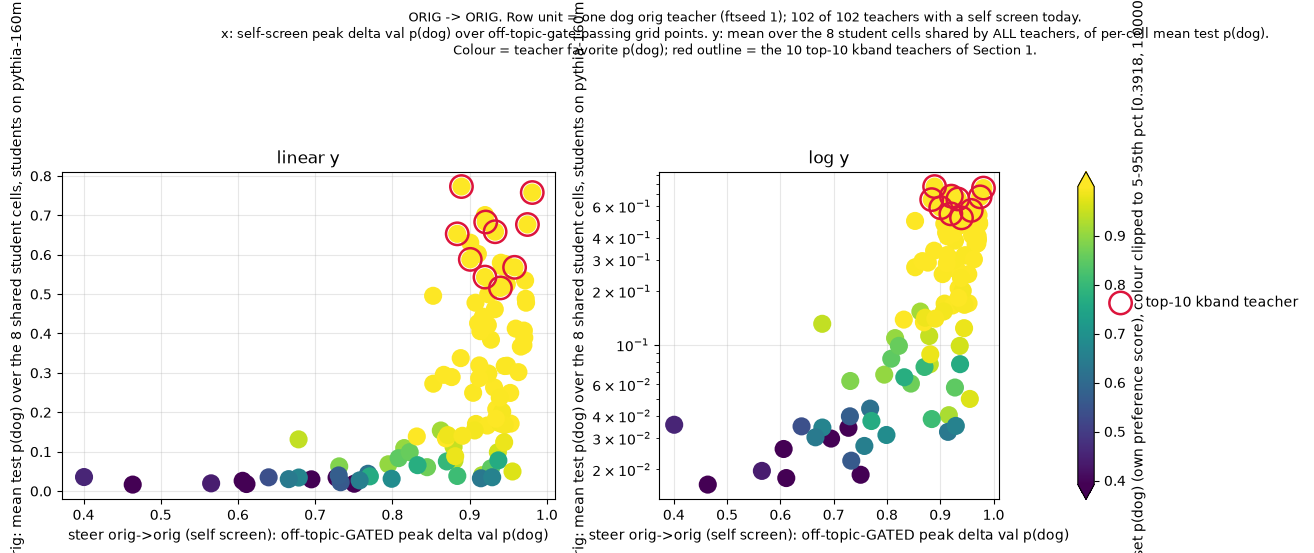

In [12]:
s2_fav = [json.loads((OUT / "teachers/dog/pythia-160m" / t / "steerability/self/aggregate.json")
                     .read_text())["teacher_pos_p_mean"] for t in s2["teacher"]]
cvals = np.asarray(s2_fav, dtype=float)
cvmin, cvmax = np.percentile(cvals, 5), np.percentile(cvals, 95)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, logy in zip(axes, [False, True]):
    sc = ax.scatter(s2["gated_off_delta"], s2["transfer_mean"], s=170, c=s2_fav,
                    cmap="viridis", vmin=cvmin, vmax=cvmax,
                    edgecolor="none", zorder=3)
    top = s2[s2["top10"]]
    ax.scatter(top["gated_off_delta"], top["transfer_mean"], s=260, facecolor="none",
               edgecolor="crimson", linewidth=1.8, zorder=4, label="top-10 kband teacher")
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("steer orig->orig (self screen): off-topic-GATED peak delta val p(dog)")
    ax.set_ylabel(f"transfer orig->orig: mean test p(dog) over the {n_shared_cells} "
                  "shared student cells, students on pythia-160m")
    ax.set_title("log y" if logy else "linear y")
    ax.grid(alpha=0.3)
axes[1].legend(loc="center left", bbox_to_anchor=(1.28, 0.6), frameon=False)
cb = fig.colorbar(sc, ax=axes[1], pad=0.16, extend="both")
cb.set_label("teacher favorite-set p(dog) (own preference score), colour clipped to "
             f"5-95th pct [{cvmin:.4f}, {cvmax:.4f}]")
fig.suptitle(f"ORIG -> ORIG. Row unit = one dog orig teacher (ftseed 1); {len(s2)} of {M} teachers with a self "
             "screen today.\nx: self-screen peak delta val p(dog) over off-topic-gate-passing "
             f"grid points. y: mean over the {n_shared_cells} student cells shared by ALL teachers, "
             "of per-cell mean test "
             "p(dog).\nColour = teacher favorite p(dog); red outline = the 10 top-10 kband teachers of "
             "Section 1.", fontsize=9)
fig.tight_layout(rect=(0, 0, 0.88, 0.87))
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)
fig.savefig(FIGDIR / "steerability_vs_transfer_gatedoff_teachers.png", dpi=150,
            bbox_inches="tight")
plt.show()

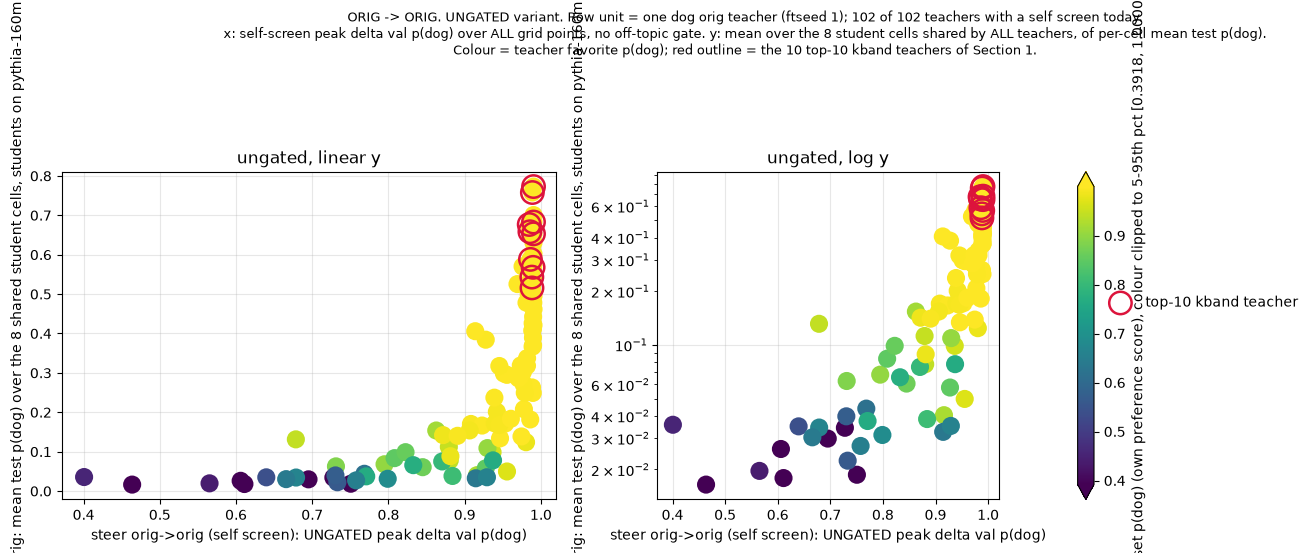

In [13]:
s2_fav = [json.loads((OUT / "teachers/dog/pythia-160m" / t / "steerability/self/aggregate.json")
                     .read_text())["teacher_pos_p_mean"] for t in s2["teacher"]]
# UNGATED counterpart of the figure above (same panels/markers/legend), x = ungated_delta.
cvals = np.asarray(s2_fav, dtype=float)
cvmin, cvmax = np.percentile(cvals, 5), np.percentile(cvals, 95)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, logy in zip(axes, [False, True]):
    sc = ax.scatter(s2["ungated_delta"], s2["transfer_mean"], s=170, c=s2_fav,
                    cmap="viridis", vmin=cvmin, vmax=cvmax,
                    edgecolor="none", zorder=3)
    top = s2[s2["top10"]]
    ax.scatter(top["ungated_delta"], top["transfer_mean"], s=260, facecolor="none",
               edgecolor="crimson", linewidth=1.8, zorder=4, label="top-10 kband teacher")
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("steer orig->orig (self screen): UNGATED peak delta val p(dog)")
    ax.set_ylabel(f"transfer orig->orig: mean test p(dog) over the {n_shared_cells} "
                  "shared student cells, students on pythia-160m")
    ax.set_title("ungated, log y" if logy else "ungated, linear y")
    ax.grid(alpha=0.3)
axes[1].legend(loc="center left", bbox_to_anchor=(1.28, 0.6), frameon=False)
cb = fig.colorbar(sc, ax=axes[1], pad=0.16, extend="both")
cb.set_label("teacher favorite-set p(dog) (own preference score), colour clipped to "
             f"5-95th pct [{cvmin:.4f}, {cvmax:.4f}]")
fig.suptitle(f"ORIG -> ORIG. UNGATED variant. Row unit = one dog orig teacher (ftseed 1); {len(s2)} of {M} "
             "teachers with a self screen today.\nx: self-screen peak delta val p(dog) over ALL "
             f"grid points, no off-topic gate. y: mean over the {n_shared_cells} student cells shared "
             "by ALL teachers, of "
             "per-cell mean test p(dog).\nColour = teacher favorite p(dog); red outline = the 10 top-10 "
             "kband teachers of Section 1.", fontsize=9)
fig.tight_layout(rect=(0, 0, 0.88, 0.87))
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)
fig.savefig(FIGDIR / "steerability_vs_transfer_ungated_teachers.png", dpi=150,
            bbox_inches="tight")
plt.show()


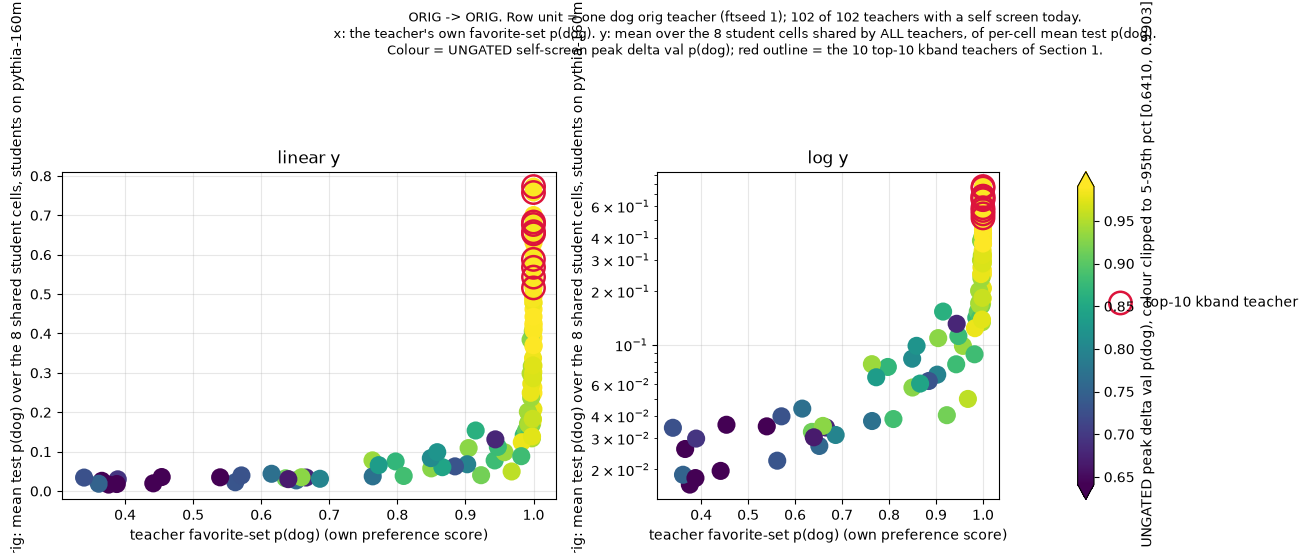

In [14]:
# Sibling of the figure above with the axes swapped in role: x = the teacher's OWN favorite-set
# p(dog) (the quantity that was only a colour above), colour = the UNGATED steer lift.
cvals = s2["ungated_delta"].to_numpy(dtype=float)
cvmin, cvmax = np.percentile(cvals, 5), np.percentile(cvals, 95)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, logy in zip(axes, [False, True]):
    sc = ax.scatter(s2_fav, s2["transfer_mean"], s=170, c=s2["ungated_delta"],
                    cmap="viridis", vmin=cvmin, vmax=cvmax, edgecolor="none", zorder=3)
    tm = s2["top10"].to_numpy()
    ax.scatter(np.asarray(s2_fav)[tm], s2["transfer_mean"].to_numpy()[tm], s=260,
               facecolor="none", edgecolor="crimson", linewidth=1.8, zorder=4,
               label="top-10 kband teacher")
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("teacher favorite-set p(dog) (own preference score)")
    ax.set_ylabel(f"transfer orig->orig: mean test p(dog) over the {n_shared_cells} "
                  "shared student cells, students on pythia-160m")
    ax.set_title("log y" if logy else "linear y")
    ax.grid(alpha=0.3)
axes[1].legend(loc="center left", bbox_to_anchor=(1.28, 0.6), frameon=False)
cb = fig.colorbar(sc, ax=axes[1], pad=0.16, extend="both")
cb.set_label("steer orig->orig: UNGATED peak delta val p(dog), colour clipped to "
             f"5-95th pct [{cvmin:.4f}, {cvmax:.4f}]")
fig.suptitle(f"ORIG -> ORIG. Row unit = one dog orig teacher (ftseed 1); {len(s2)} of {M} teachers with a self "
             "screen today.\nx: the teacher's own favorite-set p(dog). y: mean over the "
             f"{n_shared_cells} student cells shared by ALL teachers, of per-cell mean test "
             "p(dog).\nColour = UNGATED self-screen peak delta val p(dog); red outline = the 10 "
             "top-10 kband teachers of Section 1.", fontsize=9)
fig.tight_layout(rect=(0, 0, 0.88, 0.87))
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)
fig.savefig(FIGDIR / "steerability_vs_transfer_xteacherp_colour_ungated.png", dpi=150,
            bbox_inches="tight")
plt.show()


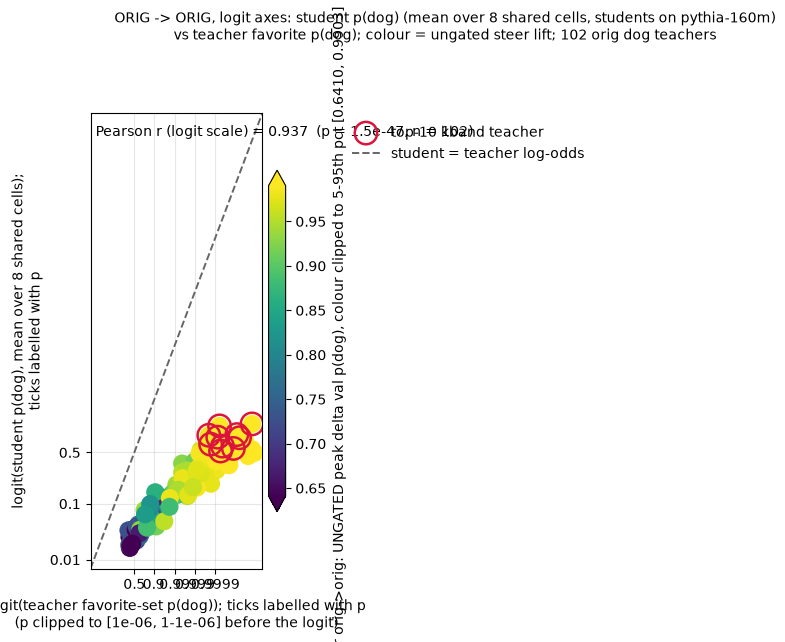

Pearson r on logit axes = 0.9372 (p = 1.51e-47), n = 102
Colour clip (ungated_delta, 5-95th pct): [0.6410, 0.9903]


In [15]:
# Logit-axis version of the figure above: both the teacher's own favorite p(dog) and the
# student transfer mean are mapped through logit(p) = log(p / (1 - p)), with p CLIPPED to
# [1e-6, 1 - 1e-6] first. One panel suffices: the logit resolves both the p->0 and p->1 ends.
EPS = 1e-6


def _logit(p):
    p = np.clip(np.asarray(p, dtype=float), EPS, 1.0 - EPS)
    return np.log(p / (1.0 - p))


x_lg = _logit(s2_fav)
y_lg = _logit(s2["transfer_mean"].to_numpy())
cvals = s2["ungated_delta"].to_numpy(dtype=float)
cvmin, cvmax = np.percentile(cvals, 5), np.percentile(cvals, 95)
r_lg = pearsonr(x_lg, y_lg)

fig, ax = plt.subplots(figsize=(9, 6.5))
sc = ax.scatter(x_lg, y_lg, s=170, c=cvals, cmap="viridis", vmin=cvmin, vmax=cvmax,
                edgecolor="none", zorder=3)
tm = s2["top10"].to_numpy()
ax.scatter(x_lg[tm], y_lg[tm], s=260, facecolor="none", edgecolor="crimson",
           linewidth=1.8, zorder=4, label="top-10 kband teacher")
lo = float(min(x_lg.min(), y_lg.min()))
hi = float(max(x_lg.max(), y_lg.max()))
pad = 0.05 * (hi - lo)
ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], ls="--", color="0.4", lw=1.4,
        zorder=2, label="student = teacher log-odds")

# Ticks at the logit of round p values; label them with the p value itself.
P_HI = [0.5, 0.9, 0.99, 0.999, 0.9999]
P_LO = [0.01, 0.1]


def _pticks(ax_, axis, values, lo_, hi_):
    keep = [(p, _logit(p)) for p in values if lo_ - pad <= _logit(p) <= hi_ + pad]
    if not keep:
        return
    pos = [v for _, v in keep]
    lab = [("%g" % p) for p, _ in keep]
    (ax_.set_xticks if axis == "x" else ax_.set_yticks)(pos)
    (ax_.set_xticklabels if axis == "x" else ax_.set_yticklabels)(lab)


_pticks(ax, "x", P_HI, float(x_lg.min()), float(x_lg.max()))
_pticks(ax, "y", sorted(P_LO + P_HI), float(y_lg.min()), float(y_lg.max()))
ax.set_xlim(lo - pad, hi + pad)
ax.set_ylim(lo - pad, hi + pad)
ax.set_xlabel("logit(teacher favorite-set p(dog)); ticks labelled with p\n"
              f"(p clipped to [{EPS:g}, 1-{EPS:g}] before the logit)")
ax.set_ylabel(f"logit(student p(dog), mean over {n_shared_cells} shared cells);\n"
              "ticks labelled with p")
ax.annotate(f"Pearson r (logit scale) = {r_lg.statistic:.3f}  (p = {r_lg.pvalue:.2g}, "
            f"n = {len(s2)})", xy=(0.03, 0.95), xycoords="axes fraction", fontsize=10)
ax.grid(alpha=0.3)
ax.legend(loc="upper left", bbox_to_anchor=(1.45, 1.0), frameon=False)
cb = fig.colorbar(sc, ax=ax, pad=0.03, shrink=0.75, extend="both")
cb.set_label("steer orig->orig: UNGATED peak delta val p(dog), colour clipped to "
             f"5-95th pct [{cvmin:.4f}, {cvmax:.4f}]")
fig.suptitle("ORIG -> ORIG, logit axes: student p(dog) (mean over "
             f"{n_shared_cells} shared cells, students on pythia-160m)\nvs teacher favorite "
             "p(dog); colour = ungated steer lift; "
             f"{len(s2)} orig dog teachers", fontsize=10)
fig.tight_layout(rect=(0, 0, 0.78, 0.92))
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)
fig.savefig(FIGDIR / "steerability_logit_student_vs_teacher.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Pearson r on logit axes = {r_lg.statistic:.4f} (p = {r_lg.pvalue:.3g}), n = {len(s2)}")
print(f"Colour clip (ungated_delta, 5-95th pct): [{cvmin:.4f}, {cvmax:.4f}]")


FIXED = ep10_lr1e-4_r8a32: the alphabetically-first of the 8 SHARED2 cells (held, like all of them, by all 102 teachers).


Row unit: one teacher with a self screen; n = 102.
transfer_fixed_cell: that ONE shared cell's per-cell mean test p(dog) (ftseeds averaged).
  transfer_fixed_cell vs gated_off_delta: spearman 0.600, pearson 0.496
  transfer_fixed_cell vs ungated_delta: spearman 0.855, pearson 0.603


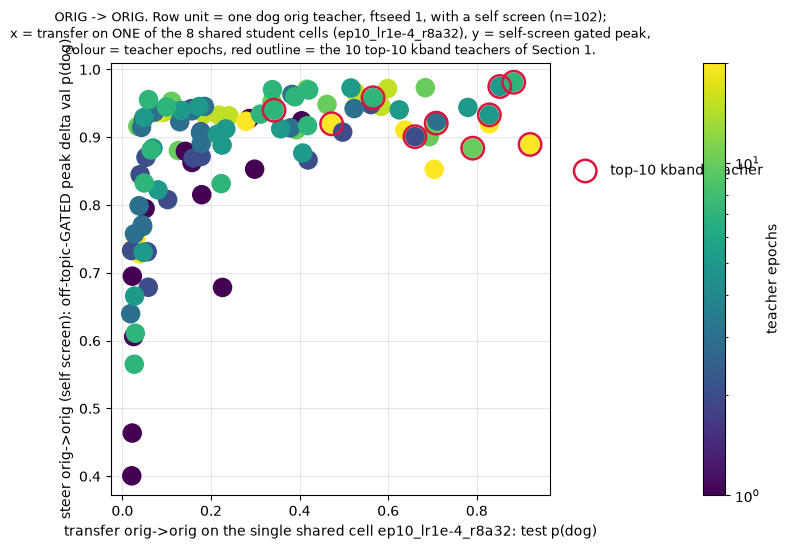

In [16]:
# Secondary check: hold transfer to ONE of the shared cells (SHARED2), so the teacher-side
# comparison is on a single fixed student recipe rather than a mean over the shared set.
FIXED = sorted(SHARED2)[0]
print(f"FIXED = {FIXED}: the alphabetically-first of the {n_shared_cells} SHARED2 cells "
      f"(held, like all of them, by all {M} teachers).")

fx = []
for _, row in t2[t2["has_screen"]].iterrows():
    v = cell_scores(row["teacher"], "pythia-160m")[FIXED]
    fx.append({"teacher": row["teacher"], "epochs": row["epochs"], "top10": row["top10"],
               "transfer_fixed_cell": v, "gated_off_delta": row["gated_off_delta"],
               "ungated_delta": row["ungated_delta"]})
fxd = pd.DataFrame(fx)
print(f"Row unit: one teacher with a self screen; n = {len(fxd)}.")
print("transfer_fixed_cell: that ONE shared cell's per-cell mean test p(dog) (ftseeds averaged).")
for m in ["gated_off_delta", "ungated_delta"]:
    print(f"  transfer_fixed_cell vs {m}: spearman "
          f"{spearmanr(fxd['transfer_fixed_cell'], fxd[m]).statistic:.3f}, pearson "
          f"{pearsonr(fxd['transfer_fixed_cell'], fxd[m]).statistic:.3f}")

fig, ax = plt.subplots(figsize=(9.5, 5.6))
s = ax.scatter(fxd["transfer_fixed_cell"], fxd["gated_off_delta"], s=170, c=fxd["epochs"],
               cmap="viridis", norm=plt.matplotlib.colors.LogNorm(), zorder=3)
tp = fxd[fxd["top10"]]
ax.scatter(tp["transfer_fixed_cell"], tp["gated_off_delta"], s=260, facecolor="none",
           edgecolor="crimson", linewidth=1.8, zorder=4, label="top-10 kband teacher")
ax.set_xlabel(f"transfer orig->orig on the single shared cell {FIXED}: test p(dog)")
ax.set_ylabel("steer orig->orig (self screen): off-topic-GATED peak delta val p(dog)")
ax.grid(alpha=0.3)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.75), frameon=False)
cb = fig.colorbar(s, ax=ax, pad=0.22)
cb.set_label("teacher epochs")
ax.set_title(f"ORIG -> ORIG. Row unit = one dog orig teacher, ftseed 1, with a self screen "
             f"(n={len(fxd)});\nx = transfer on ONE of the {n_shared_cells} shared student cells "
             f"({FIXED}), y = self-screen gated peak,\ncolour = teacher epochs, red outline = "
             "the 10 top-10 kband teachers of Section 1.", fontsize=9)
fig.tight_layout(rect=(0, 0, 0.82, 1))
plt.show()


CONTROL DISTRIBUTIONS (row unit: one dog orig teacher, ftseed 1; n = 102 )
  teacher_fav_p: min 0.339700  median 0.996687  max 0.999999  | >= 0.99: 61 of 102
  teacher_val_p: min 0.324172  median 0.996736  max 0.999997  | >= 0.99: 60 of 102

WHAT IS BEING PARTIALLED OUT (zero-order Spearman against each control):
  transfer_mean          vs teacher_fav_p: rho +0.939  p 2.96e-48
  transfer_fixed_cell    vs teacher_fav_p: rho +0.911  p 2.94e-40
  ungated_delta          vs teacher_fav_p: rho +0.950  p 2.15e-52
  gated_off_delta        vs teacher_fav_p: rho +0.651  p 1.34e-13
  transfer_mean          vs teacher_val_p: rho +0.951  p 1.16e-52
  transfer_fixed_cell    vs teacher_val_p: rho +0.926  p 4.08e-44
  ungated_delta          vs teacher_val_p: rho +0.946  p 8.88e-51
  gated_off_delta        vs teacher_val_p: rho +0.646  p 2.39e-13

Row unit: one (transfer axis x steer metric) pair; 2 x 2 = 4 rows, each over the same
  n = 102 dog orig teachers (ftseed 1) that have a self screen and a s

zero_order_rho  zero_order_p  partial|fav_rho  partial|fav_p  partial|val_rho  partial|val_p    n
transfer_axis       steer_metric                                                                                                      
transfer_mean       ungated_delta            0.8844           0.0          -0.0752         0.4547          -0.1509         0.1319  102
                    gated_off_delta          0.6397           0.0           0.1097         0.2749           0.1097         0.2746  102
transfer_fixed_cell ungated_delta            0.8547           0.0          -0.0845         0.4011          -0.1759         0.0785  102
                    gated_off_delta          0.6000           0.0           0.0230         0.8196           0.0074         0.9414  102

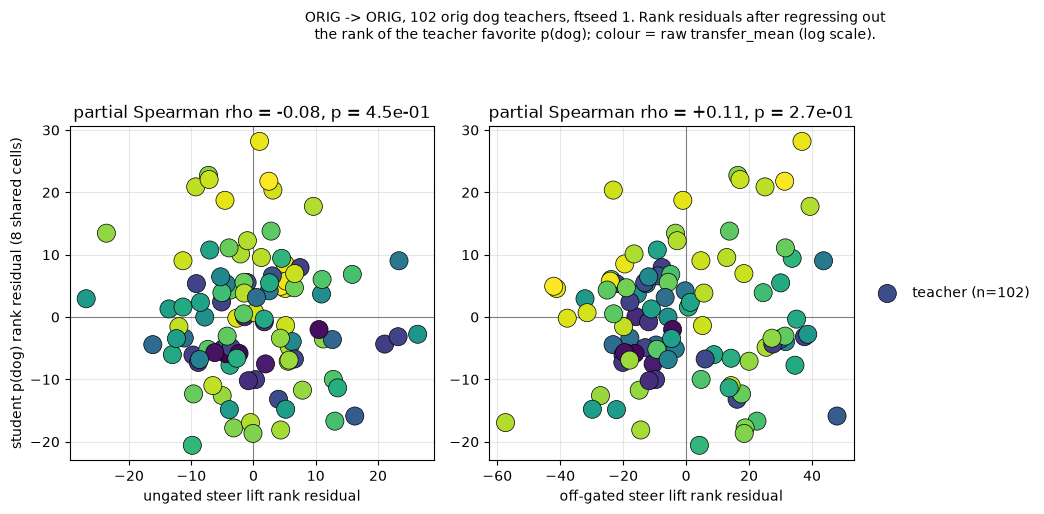

In [17]:
# Partial correlations: does the screen->transfer relation survive holding the teacher's own
# preference score fixed?  Controls are the teacher's own p(dog) on the favorite set
# (`teacher_pos_p_mean`) and on the validation set (`teacher_val_p_mean`), both read from the
# same `steerability/self/aggregate.json` as the screen columns.
def _agg_teacher_ps(tag: str) -> dict:
    d = json.loads((OUT / "teachers/dog/pythia-160m" / tag / "steerability/self/aggregate.json").read_text())
    return {"teacher_fav_p": d["teacher_pos_p_mean"], "teacher_val_p": d["teacher_val_p_mean"]}


def partial_spearman(x, y, z):
    """Partial Spearman: Pearson r of the residuals of rank(x) and rank(y) after regressing each
    on rank(z) (with intercept). Returns (r, two-sided p from t with n-3 dof, n)."""
    x, y, z = (np.asarray(v, dtype=float) for v in (x, y, z))
    rx, ry, rz = (pd.Series(v).rank().to_numpy() for v in (x, y, z))
    A = np.column_stack([np.ones_like(rz), rz])
    res = lambda v: v - A @ np.linalg.lstsq(A, v, rcond=None)[0]  # noqa: E731
    ex, ey = res(rx), res(ry)
    n = len(x)
    r = float(ex @ ey / np.sqrt((ex @ ex) * (ey @ ey)))
    t = r * np.sqrt((n - 3) / max(1 - r**2, 1e-300))
    from scipy.stats import t as _t
    return r, float(2 * _t.sf(abs(t), n - 3)), n


ps = pd.DataFrame([{"teacher": t, **_agg_teacher_ps(t)} for t in t2["teacher"]])
pc = (t2[["teacher", "transfer_mean", "gated_off_delta", "ungated_delta"]]
      .merge(ps, on="teacher")
      .merge(fxd[["teacher", "transfer_fixed_cell"]], on="teacher")
      .dropna())

print("CONTROL DISTRIBUTIONS (row unit: one dog orig teacher, ftseed 1; n =", len(pc), ")")
for c in ["teacher_fav_p", "teacher_val_p"]:
    v = pc[c]
    print(f"  {c}: min {v.min():.6f}  median {v.median():.6f}  max {v.max():.6f}  "
          f"| >= 0.99: {int((v >= 0.99).sum())} of {len(v)}")

AXES = ["transfer_mean", "transfer_fixed_cell"]
METRICS = ["ungated_delta", "gated_off_delta"]
CTRL = ["teacher_fav_p", "teacher_val_p"]

print("\nWHAT IS BEING PARTIALLED OUT (zero-order Spearman against each control):")
for c in CTRL:
    for v in AXES + METRICS:
        s = spearmanr(pc[v], pc[c])
        print(f"  {v:22s} vs {c}: rho {s.statistic:+.3f}  p {s.pvalue:.2e}")

prows = []
for ax_ in AXES:
    for m in METRICS:
        s0 = spearmanr(pc[ax_], pc[m])
        row = {"transfer_axis": ax_, "steer_metric": m,
               "zero_order_rho": s0.statistic, "zero_order_p": s0.pvalue}
        for c in CTRL:
            r, p, _n = partial_spearman(pc[ax_], pc[m], pc[c])
            row[f"partial|{c.replace('teacher_', '').replace('_p', '')}_rho"] = r
            row[f"partial|{c.replace('teacher_', '').replace('_p', '')}_p"] = p
        row["n"] = len(pc)
        prows.append(row)
partial_tbl = pd.DataFrame(prows).set_index(["transfer_axis", "steer_metric"])

print("\nRow unit: one (transfer axis x steer metric) pair; 2 x 2 = 4 rows, each over the same")
print(f"  n = {len(pc)} dog orig teachers (ftseed 1) that have a self screen and a student tree.")
print(f"  transfer_mean = mean over the {n_shared_cells} SHARED student cells of per-cell mean")
print(f"  test p(dog) (ftseeds averaged first); transfer_fixed_cell = the shared cell {FIXED} only.")
print("Columns: zero_order = plain Spearman of transfer vs steer metric; partial|fav and")
print("  partial|val = partial Spearman controlling for the teacher's own favorite-set / ")
print("  validation-set p(dog) (Pearson r of rank residuals; p from t, n-3 dof).")
print("Aggregation: per-teacher values first, then one correlation across teachers.")
display(partial_tbl.round(4))

SHORT = {"ungated_delta": "ungated steer lift", "gated_off_delta": "off-gated steer lift"}
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
rz = pc["teacher_fav_p"].rank().to_numpy()
A = np.column_stack([np.ones_like(rz), rz])
resid = lambda v: v - A @ np.linalg.lstsq(A, v, rcond=None)[0]  # noqa: E731
for ax, m in zip(axes, METRICS):
    ex = resid(pc[m].rank().to_numpy())
    ey = resid(pc["transfer_mean"].rank().to_numpy())
    r, p, _n = partial_spearman(pc["transfer_mean"], pc[m], pc["teacher_fav_p"])
    ax.scatter(ex, ey, s=170, c=pc["transfer_mean"], cmap="viridis",
               norm=plt.matplotlib.colors.LogNorm(), edgecolor="black", linewidth=0.5,
               zorder=3, label=f"teacher (n={len(pc)})")
    ax.axhline(0, color="grey", lw=0.8)
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_xlabel(f"{SHORT[m]} rank residual")
    ax.set_title(f"partial Spearman rho = {r:+.2f}, p = {p:.1e}")
    ax.grid(alpha=0.3)
axes[0].set_ylabel(f"student p(dog) rank residual ({n_shared_cells} shared cells)")
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.suptitle(f"ORIG -> ORIG, {len(pc)} orig dog teachers, ftseed 1. Rank residuals after "
             "regressing out\nthe rank of the teacher favorite p(dog); colour = raw "
             "transfer_mean (log scale).", fontsize=10)
fig.tight_layout(rect=(0, 0, 0.88, 0.92))
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/steerability_partial_residuals_rank.png", dpi=150, bbox_inches="tight")
plt.show()


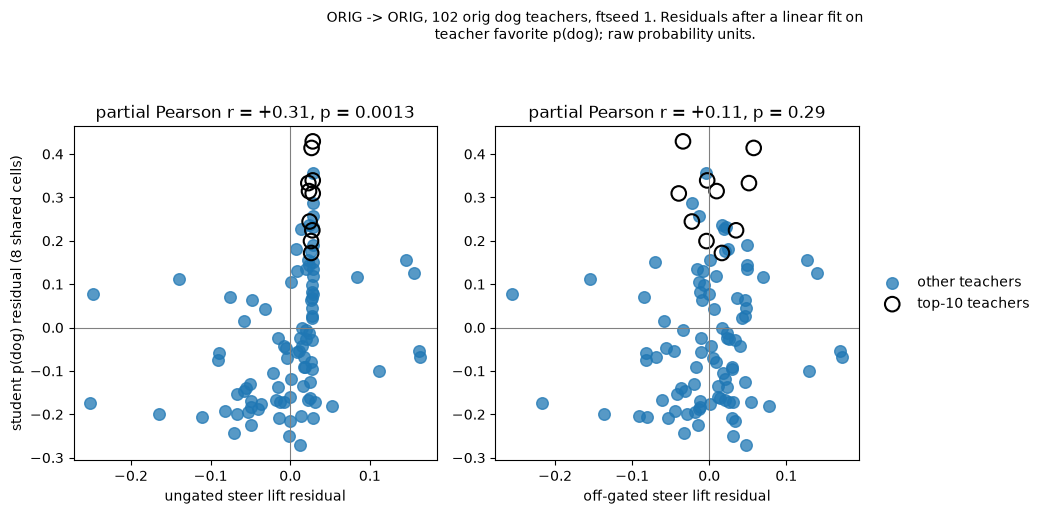

61 of 102 teachers are saturated (teacher favorite p(dog) >= 0.99); their ungated
  steer lift is pinned in [0.89, 0.99], so they share essentially one common x-residual (the
  vertical stripe in the left panel), while their transfer spreads 0.13-0.77 in raw p(dog).
The raw ungated partial r is carried by that stripe - a saturation / heteroscedasticity
  artefact - whereas the rank partial collapses those ties, which is why the two differ
  in sign. Off-stripe check: same raw partial on the non-saturated teachers only
  (teacher favorite p(dog) < 0.99, n = 41):
  ungated_delta      all n=102: r +0.314 (p 0.0013)   | fav_p<0.99 n=41: r -0.126 (p 0.43)
  gated_off_delta    all n=102: r +0.106 (p 0.29)   | fav_p<0.99 n=41: r -0.165 (p 0.3)


In [18]:
# Same partial, in RAW units (not ranks): residualise each variable on the teacher's own
# favorite-set p(dog) with a straight-line fit, then plot residual vs residual. The annotated
# r is the partial PEARSON correlation (Pearson r of the two residual vectors).
# Row unit: one dog orig teacher (ftseed 1), n = len(pc); x/y in the variables' native units
# (probabilities), minus the linear teacher-p(dog) fit.
from scipy.stats import t as _t


def _resid_raw(v, z):
    A = np.column_stack([np.ones(len(z)), np.asarray(z, float)])
    v = np.asarray(v, float)
    return v - A @ np.linalg.lstsq(A, v, rcond=None)[0]


def _partial_pearson_raw(m, mask=None):
    """Partial Pearson r of transfer_mean vs steer metric `m`, controlling for teacher_fav_p,
    in raw probability units. `mask` optionally restricts the teacher subset."""
    d = pc if mask is None else pc[mask]
    ex = _resid_raw(d[m], d["teacher_fav_p"])
    ey = _resid_raw(d["transfer_mean"], d["teacher_fav_p"])
    r = float(np.corrcoef(ex, ey)[0, 1])
    n = len(d)
    t = r * np.sqrt((n - 2) / max(1 - r**2, 1e-300))
    return r, float(2 * _t.sf(abs(t), n - 2)), n, ex, ey


ctrl = "teacher_fav_p"
SHORT = {"ungated_delta": "ungated steer lift", "gated_off_delta": "off-gated steer lift"}
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax_, m in zip(axes, METRICS):
    r, p, n, ex, ey = _partial_pearson_raw(m)
    top = pc["teacher"].isin(t2.loc[t2["top10"].astype(bool), "teacher"]).to_numpy()
    ax_.scatter(ex[~top], ey[~top], s=70, alpha=0.75, label="other teachers")
    ax_.scatter(ex[top], ey[top], s=110, facecolors="none", edgecolors="k", linewidths=1.5,
                label="top-10 teachers")
    ax_.axhline(0, color="grey", lw=0.8)
    ax_.axvline(0, color="grey", lw=0.8)
    ax_.set_xlabel(f"{SHORT[m]} residual")
    ax_.set_title(f"partial Pearson r = {r:+.2f}, p = {p:.2g}")
axes[0].set_ylabel(f"student p(dog) residual ({n_shared_cells} shared cells)")
axes[-1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.suptitle(f"ORIG -> ORIG, {len(pc)} orig dog teachers, ftseed 1. Residuals after a linear fit "
             "on\nteacher favorite p(dog); raw probability units.", fontsize=10)
fig.tight_layout(rect=(0, 0, 0.88, 0.92))
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/steerability_partial_residuals_raw.png", dpi=150, bbox_inches="tight")
plt.show()

# WHY THE RAW AND RANK PARTIALS DISAGREE, and the same partial off the saturated stripe.
sat = (pc["teacher_fav_p"] >= 0.99).to_numpy()
off = ~sat
print(f"{int(sat.sum())} of {len(pc)} teachers are saturated (teacher favorite p(dog) >= 0.99); "
      f"their ungated\n  steer lift is pinned in "
      f"[{pc.loc[sat, 'ungated_delta'].min():.2f}, {pc.loc[sat, 'ungated_delta'].max():.2f}], so "
      "they share essentially one common x-residual (the\n  vertical stripe in the left panel), "
      f"while their transfer spreads {pc.loc[sat, 'transfer_mean'].min():.2f}-"
      f"{pc.loc[sat, 'transfer_mean'].max():.2f} in raw p(dog).")
print("The raw ungated partial r is carried by that stripe - a saturation / heteroscedasticity")
print("  artefact - whereas the rank partial collapses those ties, which is why the two differ")
print("  in sign. Off-stripe check: same raw partial on the non-saturated teachers only")
print(f"  (teacher favorite p(dog) < 0.99, n = {int(off.sum())}):")
for m in METRICS:
    r_all, p_all, n_all, _, _ = _partial_pearson_raw(m)
    r_off, p_off, n_off, _, _ = _partial_pearson_raw(m, off)
    print(f"  {m:18s} all n={n_all}: r {r_all:+.3f} (p {p_all:.2g})   "
          f"| fav_p<0.99 n={n_off}: r {r_off:+.3f} (p {p_off:.2g})")


## Conclusion

**The off-topic-gated screen separates receivers.** Mean gated peak delta val p(dog) over the
10 teachers is 0.930 (orig), 0.829 (ds2), 0.662 (ds3), 0.511 (ds1) — then a cliff — 0.006 (fs3),
0.0044 (fs1), 0.0031 (wc1), 0.0012 (fs2). Mean transfer over the 56 shared cells follows the same
two-tier split: 0.605 (orig), 0.058 (ds2), 0.042 (ds1), 0.041 (ds3) versus 0.019 (fs3), 0.0093
(fs1), 0.0070 (fs2), i.e. 62.9x / 5.3x / 3.1x / 4.5x the base dog test prior for the data-seed
lineages against 1.7x / 1.1x / 0.8x for the fully re-seeded ones. So the gated screen calls the
*steerable* lineages (orig, ds*) apart from the *unsteerable* ones (fs*, wc1) exactly as transfer
does, and wc1's screen values (0.0022–0.0048) place it with the fs receivers — a prediction we
cannot check, since wc1 has no transfer side. Within the steerable tier the ordering is not
reproduced: the screen ranks ds2 > ds3 > ds1 while transfer ranks ds2 > ds1 ~ ds3, and orig's
screen advantage over ds2 (0.930 vs 0.829, a factor 1.12) is nothing like its transfer advantage
(0.605 vs 0.058, a factor 10.5). The pooled 70-row correlation (Spearman 0.874, Pearson 0.603 on
the gated metric) is a restatement of the two-tier receiver split, not evidence about teachers.

**Within a receiver (n=10) the screen does not rank teachers.** Gated Spearman is -0.297 (orig),
0.442 (ds1), 0.115 (ds2), -0.539 (ds3), -0.079 (fs1), -0.212 (fs2), -0.285 (fs3): five of seven
negative, none near the |rho| ~ 0.65 needed for p=0.05 at n=10, and the sign is unstable across
lineages that differ only in a training seed. The ungated column is no better (0.406 / 0.442 /
-0.103 / -0.382 / -0.079 / -0.212 / -0.285) and gated_neg_off is worse still. On the three fs
receivers the gated, ungated and gated_neg_off columns are numerically identical, because at
delta ~ 0.005 the peak grid point passes every gate — there is nothing to gate.

**Across the wide teacher population the screen does rank teachers, moderately.** All 102
teachers are screened, and transfer — mean over the 8 student cells shared by every one of them,
so the comparison is cell-matched by construction — correlates with the gated delta at Spearman
0.640 (p=4e-13) and Pearson 0.552; the ungated delta does better still, Spearman 0.884 (p<1e-34),
Pearson 0.653, while gated_neg_off is flat (0.035, p=0.73). Holding transfer to a single one of
those shared cells — `ep10_lr1e-4_r8a32`, the alphabetically-first — gives Spearman 0.600 gated /
0.855 ungated, i.e. the same picture. The reason Section 1 sees nothing and Section 2 sees a lot
is range: the top-10 kband teachers all sit at gated delta 0.88–0.98, whereas the full population
runs from 0.40 (ep1_lr5e-4_r8a32) to 0.98, and the weak teachers at the bottom of that range are
exactly the weak distillers (ep1 teachers: transfer 0.016–0.38).

**Holding the teacher's own preference score fixed kills the teacher-level relation.** The
teacher's own favorite-set p(dog) (`teacher_pos_p_mean`) is itself saturated for most of the
population (median 0.9967, 61 of 102 at >= 0.99, but a long lower tail down to 0.340), and it
tracks both sides of the correlation almost perfectly: Spearman 0.939 with shared-cell transfer and
0.950 with the ungated delta (0.651 with the gated delta). Partialling it out on the ranks leaves
nothing: transfer_mean vs ungated_delta falls from 0.884 to -0.075 (p=0.45) and vs gated_off_delta
from 0.640 to 0.110 (p=0.27); on the shared cell `ep10_lr1e-4_r8a32` it falls from 0.855 to -0.085
and from 0.600 to 0.023. Controlling for the validation-set score instead gives the same picture
(-0.151 / 0.110 / -0.176 / 0.007, all p > 0.07). So the Section-2 "screen ranks teachers" result
is not screen-specific information: both the screen and distillation transfer are reading the same
underlying quantity, how strongly the teacher itself prefers dog, and the screen adds no ranking
signal once that is held fixed.

**Caveats.**
- *Teacher validation score is useless as a predictor and is not reported.* `teacher_val_p_mean`
  is 0.99956–0.99999 for all 10 Section-1 teachers — saturated — so a correlation column against
  it would be noise on a constant. It has been dropped everywhere.
- *Section 2 transfer is restricted to 8 shared cells.* Every Section-2 teacher is scored on the
  same 8 student cells (the intersection over all 102); the extra cells the top-10 teachers carry
  (63, 73 or 518 each) are ignored, so no teacher is advantaged by its cell mix — but the 8 cells
  are a narrow, low-rank slice of the student grid, not a representative sample of it.
- *Single teacher seed.* Every point is teacher ftseed 1; within-receiver teacher differences are
  not separated from teacher-seed noise.
- *The gated peaks are single grid points.* `gated_off_n` = 1 (min = max = 1) for all
  (receiver, teacher) pairs, so the "gated peak" is one surviving (layer, alpha) reading rather
  than a peak over a set.
- *wc1 has no transfer side and no prior.* Its student tree contains none of the 56 shared cells,
  and `load_priors` has no `weightc-seed1` entry, so both its transfer and x-prior columns are
  NaN by construction; it appears only as the screen-value rug in the third scatter panel.
- *Prior reference.* Transfer multiples use each receiver base's own dog `test_prior`; the
  screen's `base_val_p` is a different prompt set (`validation`) and the two must not be mixed.

**Bottom line.** The off-topic-gated steerability screen is a good cheap classifier of *which
receiver lineage* can be subliminally taught and a moderate cheap ranker of *which teacher*
teaches best when the teacher population spans a real range of strengths — but it carries no
usable signal inside an already-strong, narrow teacher slice.

The raw-unit and rank partials disagree by construction, not by substance: the 61 saturated teachers (favorite p(dog) >= 0.99), whose ungated steer lift is pinned near its ceiling, share a single common x-residual (the vertical stripe in the raw figure) while their transfer residuals spread over 0-0.4, so the positive raw partial (+0.31) is carried entirely by that stripe -- a saturation / heteroscedasticity artefact -- while the rank partial (-0.08) collapses the ties and shows no relation. The off-stripe partials, restricted to the non-saturated teachers with favorite p(dog) < 0.99, are printed with the raw figure.
